# Heart Disease Risk Prediction
## Model Experiments and Evaluation

This notebook documents the training, comparison, hyperparameter tuning, and evaluation of machine learning models for heart disease risk prediction.

### Objectives
- Train multiple baseline classification models.
- Compare model performance using stratified cross-validation.
- Optimize promising models through hyperparameter tuning.
- Evaluate tuned models on an independent test dataset.
- Identify the leading candidate model for further analysis.

**Dataset:** UCI Heart Disease Dataset (Cleveland subset)

**Target variable:** `target` (0 = No Heart Disease, 1 = Heart Disease)

**Random State:** 42

In [3]:
# ============================================================
# 1. IMPORT LIBRARIES AND PROJECT CONFIGURATION
# ============================================================

import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

# ------------------------------------------------------------
# Locate project root
# ------------------------------------------------------------

CURRENT_PATH = Path.cwd()
PROJECT_ROOT = next(
    (path for path in [CURRENT_PATH, *CURRENT_PATH.parents]
     if (path / "src").is_dir()),
    None
)
if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Could not locate project root containing the src folder."
    )
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

# ------------------------------------------------------------
# Import project modules
# ------------------------------------------------------------

from src.preprocessing import build_preprocessor
from src.train import build_model_pipelines, train_models
from src.evaluate import evaluate_classifier, print_evaluation_report
from src.model_comparison import compare_models_cv
from src.tune import tune_models

# ------------------------------------------------------------
# Display configuration
# ------------------------------------------------------------

RANDOM_STATE = 42
TEST_SIZE = 0.20
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)
sns.set_theme(style="whitegrid", palette="deep")

print("=" * 60)
print("HEART DISEASE RISK PREDICTION")
print("MODEL EXPERIMENTS")
print("=" * 60)
print(f"\nProject Root: {PROJECT_ROOT}")
print(f"Random State: {RANDOM_STATE}")
print(f"Test Size: {TEST_SIZE}")
print("\nAll libraries and project modules imported successfully!")

HEART DISEASE RISK PREDICTION
MODEL EXPERIMENTS

Project Root: d:\Documents\Projects\heart-disease-risk-prediction
Random State: 42
Test Size: 0.2

All libraries and project modules imported successfully!


In [4]:
# ============================================================
# 2. LOAD THE CLEANED DATASET
# ============================================================

DATA_PATH = PROJECT_ROOT / "data" / "processed" / "heart_disease_cleaned.csv"

# Load dataset
df = pd.read_csv(DATA_PATH)

# Separate features and target
X = df.drop(columns=["target"])
y = df["target"]

# ------------------------------------------------------------
# Dataset overview
# ------------------------------------------------------------

print("=" * 60)
print("DATASET OVERVIEW")
print("=" * 60)

print(f"\nDataset Shape       : {df.shape}")
print(f"Number of Records   : {df.shape[0]}")
print(f"Number of Features  : {X.shape[1]}")

print("\nFeature Columns:")
print(list(X.columns))

print("\nTarget Distribution:")
print(y.value_counts().sort_index().rename(
    index={0: "No Heart Disease", 1: "Heart Disease"}
))

print("\nMissing Values:")
print(df.isnull().sum()[df.isnull().sum() > 0])

print("\nDataset loaded successfully!")

DATASET OVERVIEW

Dataset Shape       : (303, 14)
Number of Records   : 303
Number of Features  : 13

Feature Columns:
['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal']

Target Distribution:
target
No Heart Disease    164
Heart Disease       139
Name: count, dtype: int64

Missing Values:
ca      4
thal    2
dtype: int64

Dataset loaded successfully!


In [5]:
# ============================================================
# 3. TRAIN-TEST SPLIT
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y
)

# ------------------------------------------------------------
# Display split information
# ------------------------------------------------------------

print("=" * 60)
print("TRAIN-TEST SPLIT SUMMARY")
print("=" * 60)
print(f"\nTraining Records : {len(X_train)}")
print(f"Testing Records  : {len(X_test)}")
print(f"\nTraining Set Shape : {X_train.shape}")
print(f"Testing Set Shape  : {X_test.shape}")
print("\nTraining Target Distribution:")
print(y_train.value_counts().sort_index())
print("\nTesting Target Distribution:")
print(y_test.value_counts().sort_index())
print("\nStratified train-test split completed successfully!")

TRAIN-TEST SPLIT SUMMARY

Training Records : 242
Testing Records  : 61

Training Set Shape : (242, 13)
Testing Set Shape  : (61, 13)

Training Target Distribution:
target
0    131
1    111
Name: count, dtype: int64

Testing Target Distribution:
target
0    33
1    28
Name: count, dtype: int64

Stratified train-test split completed successfully!


In [6]:
# ============================================================
# 4. BASELINE MODEL TRAINING
# ============================================================

# Build preprocessing pipeline
preprocessor = build_preprocessor()

# Train all six baseline models
baseline_models = train_models(
    X_train,
    y_train,
    preprocessor,
    random_state=RANDOM_STATE
)

# ------------------------------------------------------------
# Display training summary
# ------------------------------------------------------------

print("=" * 60)
print("BASELINE MODEL TRAINING SUMMARY")
print("=" * 60)
for model_name in baseline_models:
    print(f" [SUCCESS] {model_name}")
print("\nTotal Models Trained:", len(baseline_models))
print("\nAll baseline models trained successfully!")

BASELINE MODEL TRAINING SUMMARY
 [SUCCESS] Dummy Classifier
 [SUCCESS] Logistic Regression
 [SUCCESS] K-Nearest Neighbors
 [SUCCESS] Decision Tree
 [SUCCESS] Random Forest
 [SUCCESS] Support Vector Machine

Total Models Trained: 6

All baseline models trained successfully!


In [7]:
# ============================================================
# 5. BASELINE MODEL COMPARISON
# ============================================================

# Perform 5-fold stratified cross-validation
baseline_results = compare_models_cv(
    X_train,
    y_train,
    preprocessor,
    random_state=RANDOM_STATE
)

# ------------------------------------------------------------
# Display comparison results
# ------------------------------------------------------------

print("=" * 80)
print("BASELINE MODEL COMPARISON")
print("=" * 80)
display(
    baseline_results.round(4)
)

# ------------------------------------------------------------
# Save baseline comparison results
# ------------------------------------------------------------

REPORTS_DIR = PROJECT_ROOT / "reports"
REPORTS_DIR.mkdir(parents=True, exist_ok=True)
baseline_results.to_csv(
    REPORTS_DIR / "model_comparison_baseline.csv",
    index=False
)
print("\nBaseline comparison results saved successfully!")

BASELINE MODEL COMPARISON


,Model,ACCURACY Mean,ACCURACY Std,PRECISION Mean,PRECISION Std,RECALL Mean,RECALL Std,F1 Mean,F1 Std,ROC_AUC Mean,ROC_AUC Std,PR_AUC Mean,PR_AUC Std,SPECIFICITY Mean,SPECIFICITY Std
0,Dummy Classifier,0.5413,0.0065,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.5000,0.0000,0.4587,0.0065,1.0000,0.0000
1,Logistic Regression,0.8471,0.0100,0.8768,0.0542,0.7834,0.0459,0.8245,0.0069,0.9025,0.0144,0.8992,0.0212,0.9003,0.0525
2,K-Nearest Neighbors,0.8222,0.0288,0.8232,0.0311,0.7826,0.0893,0.7989,0.0426,0.8712,0.0387,0.8322,0.0548,0.8544,0.0387
3,Decision Tree,0.6980,0.0596,0.6782,0.0748,0.6842,0.0521,0.6768,0.0420,0.6967,0.0543,0.6071,0.0517,0.7091,0.1266
4,Random Forest,0.8139,0.0232,0.7967,0.0266,0.8008,0.0803,0.7958,0.0363,0.8936,0.0333,0.8971,0.0314,0.8239,0.0406
5,Support Vector Machine,0.8139,0.0235,0.8303,0.0742,0.7648,0.0797,0.7893,0.0271,0.8884,0.0240,0.8825,0.0339,0.8541,0.0825



Baseline comparison results saved successfully!


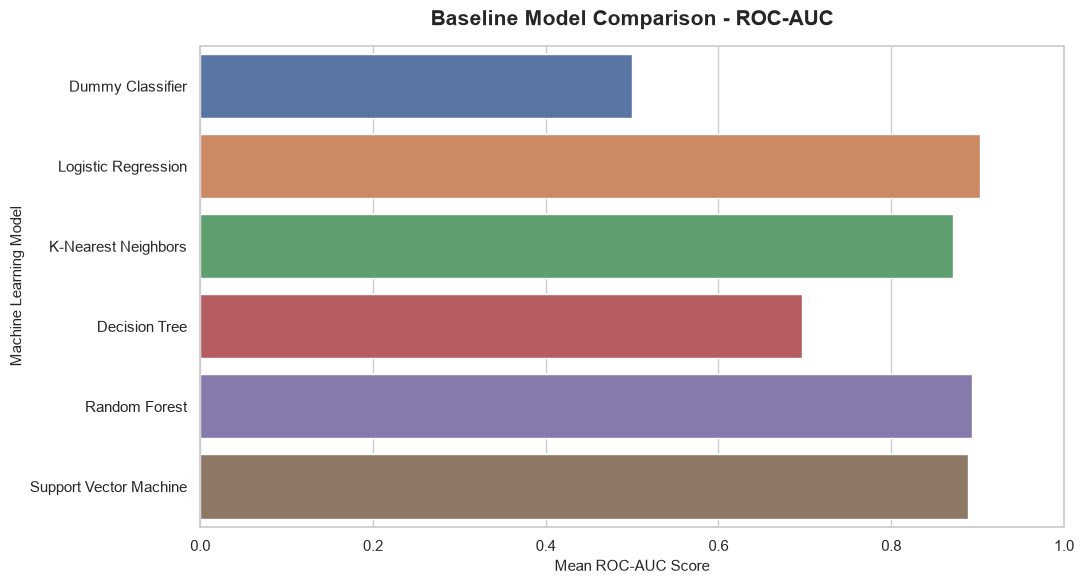

In [8]:
# ============================================================
# 6. BASELINE MODEL PERFORMANCE VISUALIZATION
# ============================================================

plt.figure(figsize=(11, 6))
sns.barplot(
    data=baseline_results,
    x="ROC_AUC Mean",
    y="Model",
    hue="Model",
    legend=False
)
plt.title(
    "Baseline Model Comparison - ROC-AUC",
    fontsize=15,
    fontweight="bold",
    pad=15
)
plt.xlabel("Mean ROC-AUC Score", fontsize=11)
plt.ylabel("Machine Learning Model", fontsize=11)
plt.xlim(0, 1)
plt.tight_layout()
plt.show()

In [9]:
# ============================================================
# 7. HYPERPARAMETER TUNING
# ============================================================

# Select promising baseline models
models_to_tune = {
    name: baseline_models[name]
    for name in [
        "Logistic Regression",
        "Random Forest",
        "Support Vector Machine",
        "K-Nearest Neighbors"
    ]
}

# Define hyperparameter search spaces
parameter_grids = {
    "Logistic Regression": {
        "classifier__C": [0.01, 0.1, 1, 10, 100],
        "classifier__solver": ["lbfgs"],
        "classifier__class_weight": [None, "balanced"]
    },
    "Random Forest": {
        "classifier__n_estimators": [200, 300, 500, 700],
        "classifier__max_depth": [None, 5, 10, 15, 20],
        "classifier__min_samples_split": [2, 5, 10],
        "classifier__min_samples_leaf": [1, 2, 4],
        "classifier__max_features": ["sqrt", "log2"],
        "classifier__class_weight": [None, "balanced"]
    },
    "Support Vector Machine": {
        "classifier__C": [0.1, 1, 10, 100],
        "classifier__kernel": ["linear", "rbf"],
        "classifier__gamma": ["scale", "auto"],
        "classifier__class_weight": [None, "balanced"]
    },
    "K-Nearest Neighbors": {
        "classifier__n_neighbors": [3, 5, 7, 9, 11, 13, 15],
        "classifier__weights": ["uniform", "distance"],
        "classifier__p": [1, 2]
    }
}

# Perform randomized hyperparameter search
best_models, tuning_results = tune_models(
    models_to_tune,
    parameter_grids,
    X_train,
    y_train,
    random_state=RANDOM_STATE,
    n_iter=30
)
print("\nHyperparameter tuning completed successfully!")


Tuning: Logistic Regression
---------------------------------------------


d:\Documents\Projects\heart-disease-risk-prediction\.venv-test\Lib\site-packages\sklearn\model_selection\_search.py:317: UserWarning: The total space of parameters 10 is smaller than n_iter=30. Running 10 iterations. For exhaustive searches, use GridSearchCV.
  warnings.warn(


Best ROC-AUC: 0.9028
Best Parameters: {'classifier__solver': 'lbfgs', 'classifier__class_weight': 'balanced', 'classifier__C': 0.1}

Tuning: Random Forest
---------------------------------------------
Best ROC-AUC: 0.9048
Best Parameters: {'classifier__n_estimators': 500, 'classifier__min_samples_split': 5, 'classifier__min_samples_leaf': 2, 'classifier__max_features': 'log2', 'classifier__max_depth': 10, 'classifier__class_weight': None}

Tuning: Support Vector Machine
---------------------------------------------
Best ROC-AUC: 0.9047
Best Parameters: {'classifier__kernel': 'linear', 'classifier__gamma': 'scale', 'classifier__class_weight': None, 'classifier__C': 0.1}

Tuning: K-Nearest Neighbors
---------------------------------------------


d:\Documents\Projects\heart-disease-risk-prediction\.venv-test\Lib\site-packages\sklearn\model_selection\_search.py:317: UserWarning: The total space of parameters 28 is smaller than n_iter=30. Running 28 iterations. For exhaustive searches, use GridSearchCV.
  warnings.warn(


Best ROC-AUC: 0.8996
Best Parameters: {'classifier__weights': 'distance', 'classifier__p': 1, 'classifier__n_neighbors': 11}

Hyperparameter tuning completed successfully!


In [10]:
# ============================================================
# 8. HYPERPARAMETER TUNING SUMMARY
# ============================================================

tuning_summary = pd.DataFrame([
    {
        "Model": model_name,
        "Best ROC-AUC": results["Best ROC-AUC"],
        "Best Parameters": results["Best Parameters"]
    }
    for model_name, results in tuning_results.items()
])
print("=" * 80)
print("HYPERPARAMETER TUNING SUMMARY")
print("=" * 80)
display(tuning_summary.round(4))

# Save tuning results
tuning_summary.to_csv(
    REPORTS_DIR / "hyperparameter_tuning_results.csv",
    index=False
)
print("\nHyperparameter tuning summary saved successfully!")

HYPERPARAMETER TUNING SUMMARY


,Model,Best ROC-AUC,Best Parameters
0,Logistic Regression,0.9028,"{'classifier__solver': 'lbfgs', 'classifier__c..."
1,Random Forest,0.9048,"{'classifier__n_estimators': 500, 'classifier_..."
2,Support Vector Machine,0.9047,"{'classifier__kernel': 'linear', 'classifier__..."
3,K-Nearest Neighbors,0.8996,"{'classifier__weights': 'distance', 'classifie..."



Hyperparameter tuning summary saved successfully!


In [11]:
# ============================================================
# 9. FINAL TEST SET EVALUATION
# ============================================================

test_results = []
print("=" * 70)
print("FINAL TEST SET EVALUATION")
print("=" * 70)
for model_name, model in best_models.items():
    # Generate predictions
    y_pred = model.predict(X_test)

    # Generate positive-class probabilities
    y_score = model.predict_proba(X_test)[:, 1]

    # Calculate evaluation metrics
    metrics = evaluate_classifier(
        y_test,
        y_pred,
        y_score
    )

    # Display evaluation report
    print_evaluation_report(
        metrics,
        model_name=model_name
    )

    # Store results
    test_results.append({
        "Model": model_name,
        "Accuracy": metrics["Accuracy"],
        "Precision": metrics["Precision"],
        "Recall": metrics["Recall"],
        "Specificity": metrics["Specificity"],
        "F1 Score": metrics["F1 Score"],
        "ROC-AUC": metrics["ROC-AUC"],
        "PR-AUC": metrics["PR-AUC"]
    })

# ------------------------------------------------------------
# Create final comparison table
# ------------------------------------------------------------

final_test_results = pd.DataFrame(test_results)
print("\nFINAL MODEL PERFORMANCE COMPARISON")
print("=" * 70)
display(final_test_results.round(4))

# Save final test results
final_test_results.to_csv(
    REPORTS_DIR / "tuned_model_test_results.csv",
    index=False
)
print("\nFinal test results saved successfully!")

FINAL TEST SET EVALUATION

             MODEL EVALUATION REPORT
  Model: Logistic Regression
------------------------------------------------------

  PERFORMANCE METRICS

  Accuracy             :     0.8852
  Precision            :     0.8387
  Recall               :     0.9286
  Specificity          :     0.8485
  F1 Score             :     0.8814
  ROC-AUC              :     0.9654
  PR-AUC               :     0.9622

  CONFUSION MATRIX
  ----------------------------------
                  Predicted
                  No     Yes
  Actual No        28      5
  Actual Yes        2     26

  TN = True Negative   FP = False Positive
  FN = False Negative  TP = True Positive

             END OF EVALUATION


             MODEL EVALUATION REPORT
  Model: Random Forest
------------------------------------------------------

  PERFORMANCE METRICS

  Accuracy             :     0.8689
  Precision            :     0.8125
  Recall               :     0.9286
  Specificity          :     0.8182
 

,Model,Accuracy,Precision,Recall,Specificity,F1 Score,ROC-AUC,PR-AUC
0,Logistic Regression,0.8852,0.8387,0.9286,0.8485,0.8814,0.9654,0.9622
1,Random Forest,0.8689,0.8125,0.9286,0.8182,0.8667,0.9491,0.9246
2,Support Vector Machine,0.8361,0.8000,0.8571,0.8182,0.8276,0.9426,0.9382
3,K-Nearest Neighbors,0.8852,0.8621,0.8929,0.8788,0.8772,0.9621,0.9518



Final test results saved successfully!


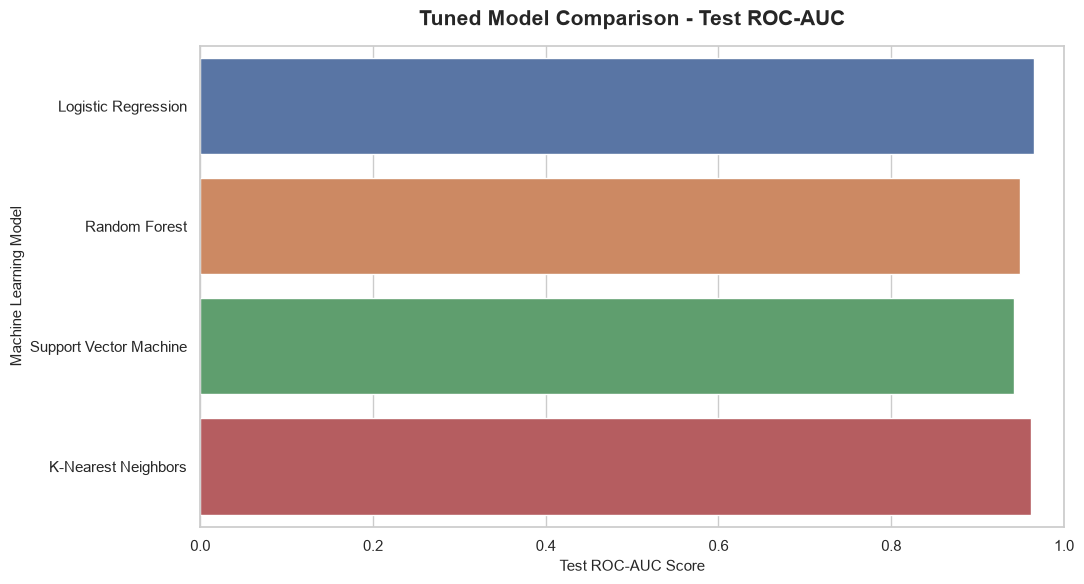

In [12]:
# ============================================================
# 10. FINAL MODEL PERFORMANCE VISUALIZATION
# ============================================================

plt.figure(figsize=(11, 6))
sns.barplot(
    data=final_test_results,
    x="ROC-AUC",
    y="Model",
    hue="Model",
    legend=False
)
plt.title(
    "Tuned Model Comparison - Test ROC-AUC",
    fontsize=15,
    fontweight="bold",
    pad=15
)
plt.xlabel("Test ROC-AUC Score", fontsize=11)
plt.ylabel("Machine Learning Model", fontsize=11)
plt.xlim(0, 1)
plt.tight_layout()
plt.show()

## 11. Experimental Results and Conclusion

### Baseline Model Comparison

Six machine learning classifiers were evaluated using 5-fold Stratified Cross-Validation.

Logistic Regression achieved the highest baseline ROC-AUC of 0.9025, followed by Random Forest (0.8936) and Support Vector Machine (0.8884).

### Hyperparameter Tuning

Four promising models were selected for hyperparameter optimization:
- Logistic Regression
- Random Forest
- Support Vector Machine
- K-Nearest Neighbors

Random Forest achieved the highest tuning cross-validation ROC-AUC of 0.9048, narrowly followed by Support Vector Machine (0.9047).

### Final Test Evaluation

The tuned models were evaluated on the independent test dataset containing 61 records.
Logistic Regression achieved the highest test ROC-AUC of 0.9654 and F1 score of 0.8814. It also achieved a recall of 0.9286.
K-Nearest Neighbors achieved the highest precision (0.8621) and specificity (0.8788), while matching Logistic Regression's accuracy of 0.8852.

### Model Selection

Logistic Regression is identified as the leading candidate for further analysis based on its overall test performance, particularly ROC-AUC, recall, and F1 score.
K-Nearest Neighbors remains a strong alternative due to its precision and specificity.

### Limitations
- The dataset contains only 303 records.
- The independent test set contains 61 records, so performance estimates have uncertainty.
- Results are based on the Cleveland subset and may not generalize to other populations.
- Model performance does not establish clinical validity or diagnostic suitability.

### Conclusion

The experiments demonstrate that multiple machine learning approaches can identify patterns associated with heart disease in the selected dataset.
Logistic Regression is carried forward as the leading candidate for explainability analysis and subsequent integration into the educational prediction application.
The models are experimental and are not intended to replace professional medical assessment.